# MLOps Assignment 01 - End-to-End Heart Disease Classification

**Course:** AIMLCZG523

**Goal:** Build a reproducible heart-disease classification workflow with EDA, model comparison, MLflow experiment tracking, model packaging, API, tests, CI/CD, containerization, deployment configuration, monitoring evidence and documentation.

## How to run this notebook

- Run cells **from top to bottom**, one at a time.
- Do not skip cells that create variables or artifacts used later.
- Keep the notebook inside the repository so the relative project paths work correctly.


## 0. Configure project paths

Set a portable project root for local development or Jupyter. Keep the project under the repository/workspace directory and avoid machine-specific paths.


In [ ]:
from pathlib import Path
import os, sys, platform, json, textwrap, subprocess, shutil, warnings
from datetime import datetime

# Portable project root: works when Jupyter starts in the repository root
# or in the notebooks/ directory.
PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# If Jupyter was opened from another directory, point this at the project root:
# PROJECT_DIR = Path.home() / "workspace" / "MLOps_Assignment_01"

DATA_RAW = PROJECT_DIR / "data" / "raw"
DATA_PROCESSED = PROJECT_DIR / "data" / "processed"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
SRC_DIR = PROJECT_DIR / "src"
TESTS_DIR = PROJECT_DIR / "tests"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
DEPLOYMENT_DIR = PROJECT_DIR / "deployment"
SCREENSHOTS_DIR = PROJECT_DIR / "screenshots"
WORKFLOWS_DIR = PROJECT_DIR / ".github" / "workflows"

for folder in [
    DATA_RAW, DATA_PROCESSED, NOTEBOOKS_DIR, SRC_DIR, TESTS_DIR,
    ARTIFACTS_DIR, DEPLOYMENT_DIR, SCREENSHOTS_DIR, WORKFLOWS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Python version:", sys.version)
print("Project directory:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())
print("Created project folders successfully.")


: 

## 1. Install the development dependencies

Install the same packages used by the repository. If the environment already has them, this cell should finish quickly.


In [ ]:
import subprocess
import sys

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "-r",
    str(PROJECT_DIR / "requirements.txt"),
])


## 2. Verify packages

In [3]:
import importlib.metadata as metadata
for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn",
                "ucimlrepo", "mlflow", "fastapi", "uvicorn", "httpx", "pytest", "ruff"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

numpy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2
ucimlrepo: 0.0.7
mlflow: 3.17.0
fastapi: 0.141.1
uvicorn: 0.54.0
httpx: 0.28.1
pytest: 8.4.2
ruff: 0.16.10


## 3. Acquire the UCI Heart Disease dataset

The dataset's target can be represented as values `0` through `4`: `0` indicates no disease and values above `0` indicate presence of disease. For a binary classification task, this notebook maps target `0` to `0` and targets `1–4` to `1`.

We will save the raw features and target to disk and inspect the schema. If the UCI endpoint is temporarily unavailable, retry this cell before changing the data source.

In [4]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

heart = fetch_ucirepo(id=45)
X_raw = heart.data.features.copy()
y_raw = heart.data.targets.copy()

print("Feature shape:", X_raw.shape)
print("Target shape:", y_raw.shape)
print("\nFeature columns:")
print(X_raw.columns.tolist())
print("\nTarget columns:")
print(y_raw.columns.tolist())
display(X_raw.head())
display(y_raw.head())

raw_df = X_raw.copy()
target_col = y_raw.columns[0]
raw_df[target_col] = y_raw[target_col].values
raw_path = DATA_RAW / "heart_disease_uci_raw.csv"
raw_df.to_csv(raw_path, index=False)
print("\nSaved raw dataset to:", raw_path)

Feature shape: (303, 13)
Target shape: (303, 1)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target columns:
['num']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


,num
0,0
1,2
2,1
3,0
4,0



Saved raw dataset to: /content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/data/raw/heart_disease_uci_raw.csv


## 4. Data quality checks and cleaning

The UCI data can contain missing values marked as `?` or encoded as missing values. We convert those to `NaN`, coerce numeric-looking columns, and report missingness. Imputation and scaling will be fitted inside the model pipeline later, which avoids fitting preprocessing on the test set.

In [5]:
df = raw_df.copy()
df = df.replace(["?", "NA", "N/A", ""], np.nan)

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Shape:", df.shape)
print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nDuplicate rows:", int(df.duplicated().sum()))
print("\nTarget distribution before binary mapping:")
display(df[target_col].value_counts(dropna=False).sort_index().to_frame("count"))

# Remove rows with missing target because a supervised target cannot be imputed reliably.
df = df.dropna(subset=[target_col]).copy()
df[target_col] = (df[target_col].astype(float) > 0).astype(int)

# Keep a clean copy; feature missing values are imputed within the sklearn pipeline.
clean_path = DATA_PROCESSED / "heart_disease_clean.csv"
df.to_csv(clean_path, index=False)

X = df.drop(columns=[target_col])
y = df[target_col].astype(int)
print("\nCleaned shape:", df.shape)
print("Binary target counts:")
display(y.value_counts().sort_index().rename(index={0: "no disease", 1: "disease"}).to_frame("count"))

Shape: (303, 14)

Missing values per column:


,missing_count
ca,4
thal,2
cp,0
trestbps,0
age,0
sex,0
fbs,0
chol,0
restecg,0
thalach,0



Duplicate rows: 0

Target distribution before binary mapping:


,count
num,
0,164
1,55
2,36
3,35
4,13



Cleaned shape: (303, 14)
Binary target counts:


,count
num,
no disease,164
disease,139


## 5. Exploratory Data Analysis (EDA)

The following visualizations cover distributions, class balance, and correlations. Numeric conversion is applied above, so these plots should be compatible with the dataset columns.

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


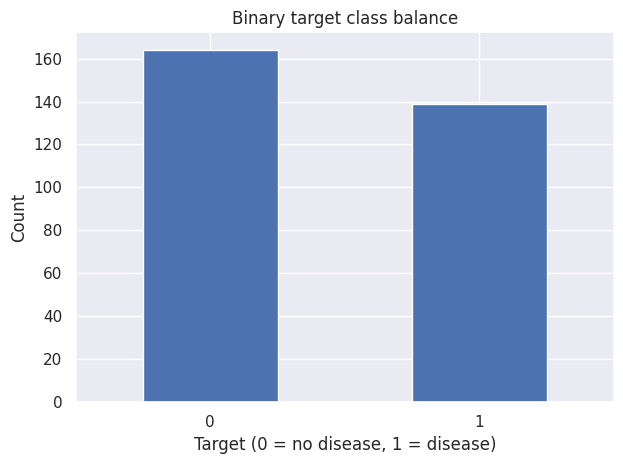

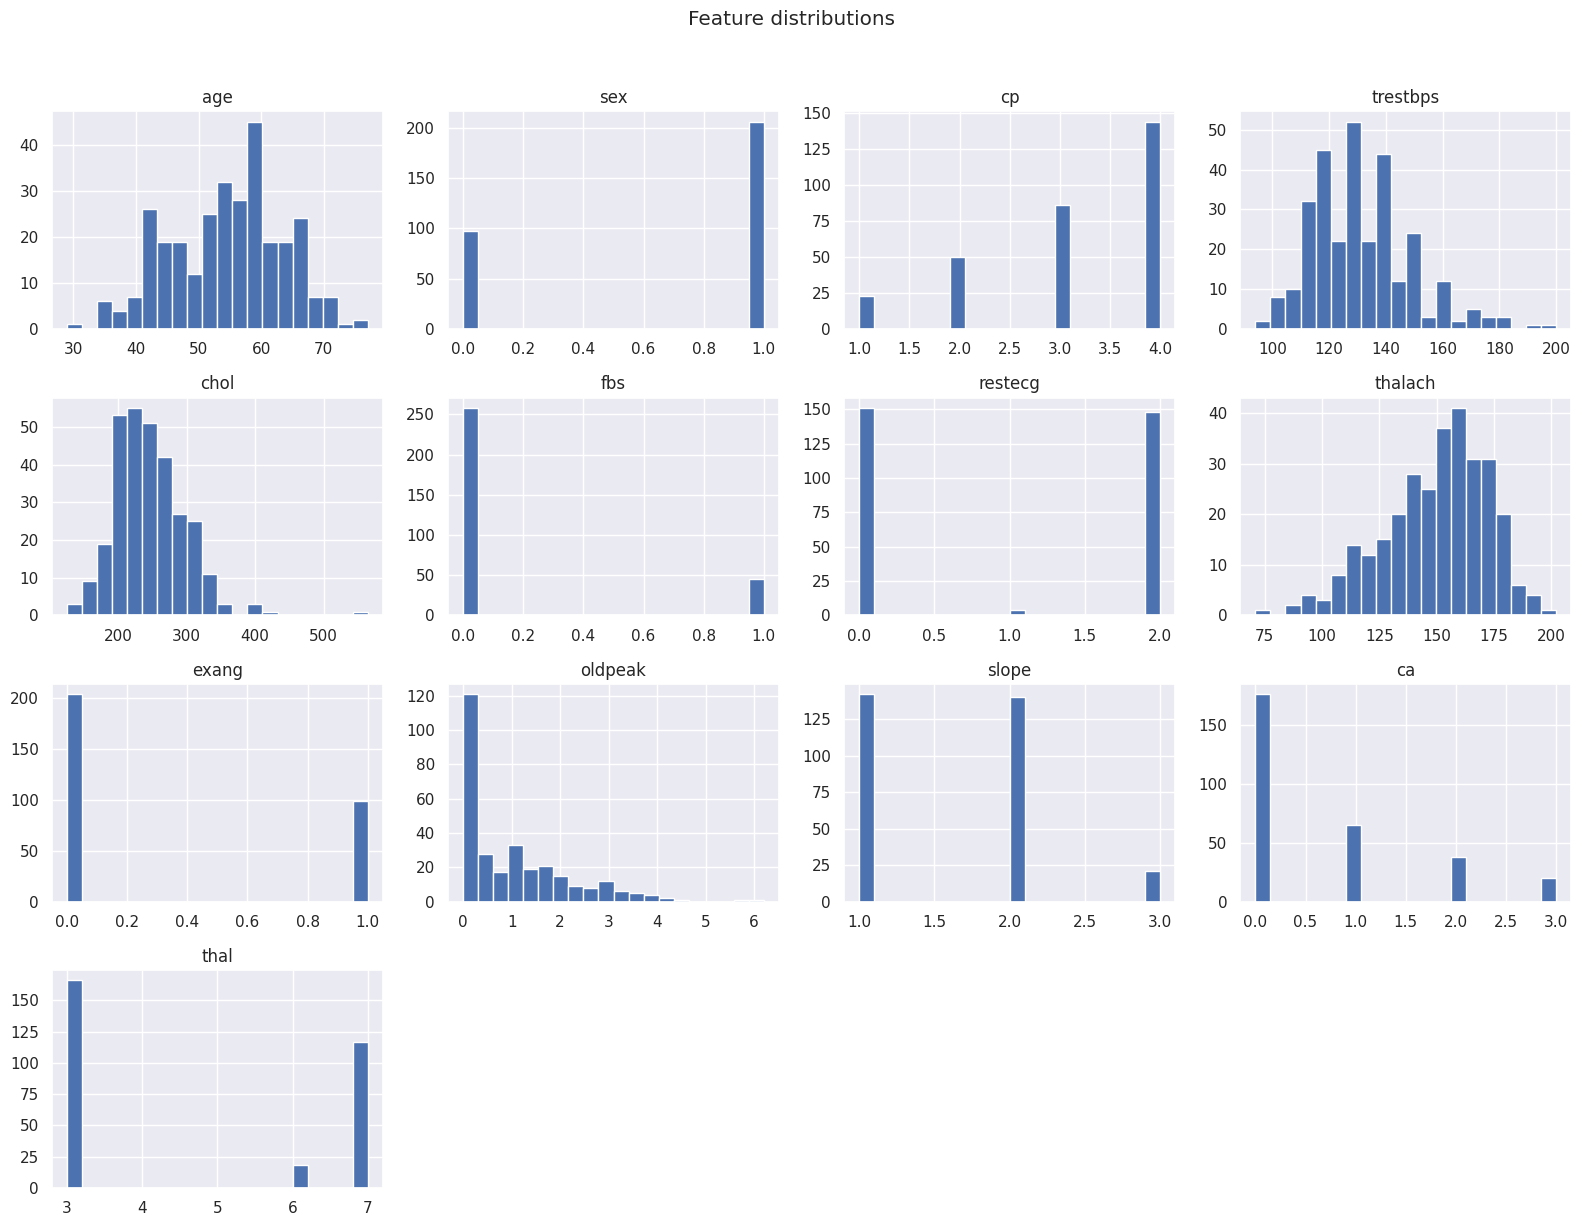

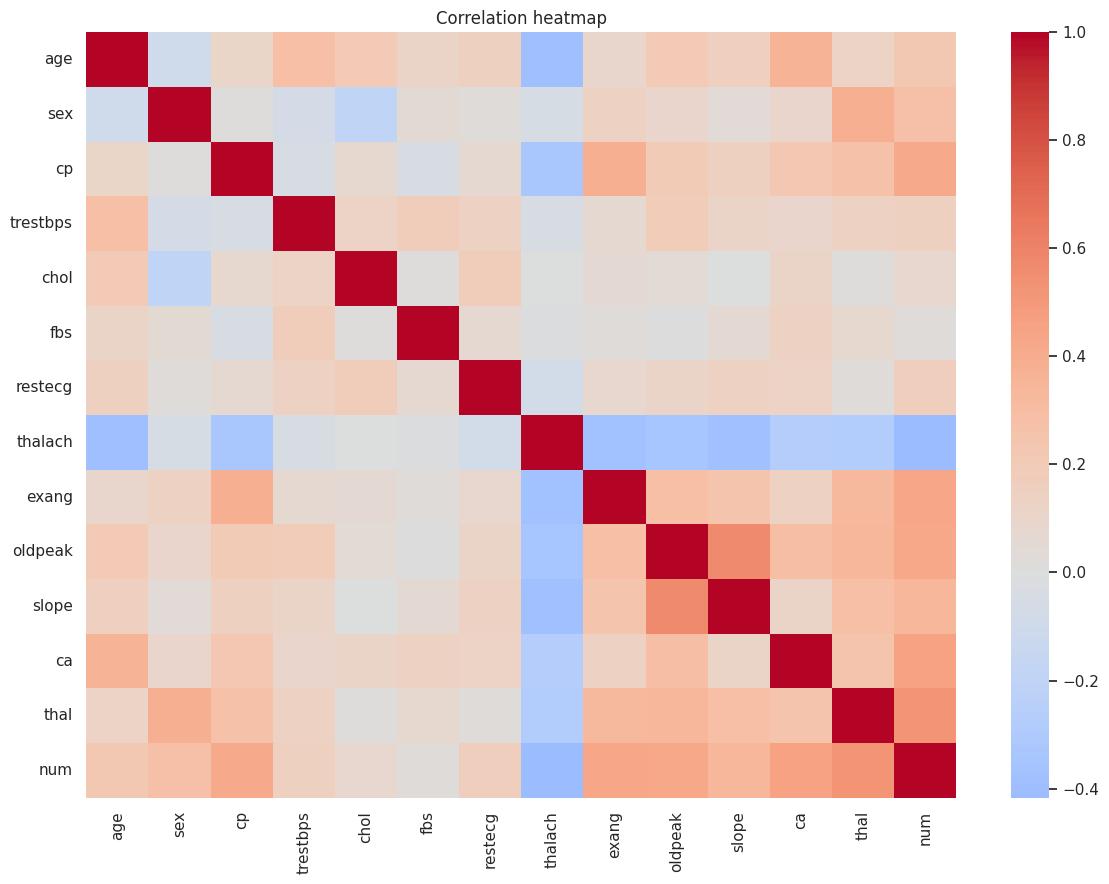

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
display(df.describe().T)

ax = y.value_counts().sort_index().plot(kind="bar", rot=0)
ax.set_title("Binary target class balance")
ax.set_xlabel("Target (0 = no disease, 1 = disease)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

df.drop(columns=[target_col]).hist(figsize=(16, 12), bins=20)
plt.suptitle("Feature distributions", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

## 6. Train/test split and preprocessing pipeline

We compare Logistic Regression and Random Forest. Numeric missing values are imputed with the median; Logistic Regression also uses standard scaling. The split is stratified to preserve class proportions. Cross-validation and final evaluation are performed on training and held-out test data respectively.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)
import numpy as np

# Remove any columns that are completely missing, as median imputation cannot recover them.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    print("Dropping entirely missing columns:", all_missing)
    X = X.drop(columns=all_missing)

numeric_features = X.columns.tolist()
numeric_preprocessor_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
numeric_preprocessor_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_scaled = ColumnTransformer([
    ("numeric", numeric_preprocessor_scaled, numeric_features)
])
preprocessor_unscaled = ColumnTransformer([
    ("numeric", numeric_preprocessor_unscaled, numeric_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "logistic_regression": Pipeline([
        ("preprocessor", preprocessor_scaled),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "random_forest": Pipeline([
        ("preprocessor", preprocessor_unscaled),
        ("model", RandomForestClassifier(
            n_estimators=300, random_state=42, class_weight="balanced",
            min_samples_leaf=2
        ))
    ])
}

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Features:", numeric_features)

Train shape: (242, 13) Test shape: (61, 13)
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


## 7. Cross-validation and model comparison

We log accuracy, precision, recall, F1 and ROC-AUC where probability estimates are available. Recall and ROC-AUC are useful here because the classes are not exactly balanced, so accuracy alone would not be enough to compare models.


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = {}
for name, pipeline in models.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, error_score="raise"
    )
    cv_results[name] = {
        metric: float(np.mean(scores[f"test_{metric}"]))
        for metric in scoring
    }

cv_df = pd.DataFrame(cv_results).T.sort_values("roc_auc", ascending=False)
display(cv_df)

,accuracy,precision,recall,f1,roc_auc
logistic_regression,0.813946,0.815373,0.773913,0.791255,0.896305
random_forest,0.801276,0.808442,0.755731,0.776478,0.884211


## 8. Hyperparameter tuning for Random Forest

This is a modest search suitable for a small dataset. We tune on the training split only. The held-out test split remains untouched until final evaluation.

In [9]:
rf_search = GridSearchCV(
    estimator=models["random_forest"],
    param_grid={
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
print("Best RF params:", rf_search.best_params_)
print("Best RF CV ROC-AUC:", round(rf_search.best_score_, 4))

# Refit logistic regression on training data for fair held-out comparison.
best_lr = models["logistic_regression"].fit(X_train, y_train)

Best RF params: {'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__n_estimators': 400}
Best RF CV ROC-AUC: 0.8917


## 9. Held-out test evaluation and model selection

Select the final model using training cross-validation results, then evaluate it on the test set. We use ROC-AUC as the selection criterion when available; record the rationale in the final report rather than choosing a model only because it has the highest accuracy.

,model,accuracy,precision,recall,f1,roc_auc
1,random_forest_tuned,0.885246,0.83871,0.928571,0.881356,0.961039
0,logistic_regression,0.868852,0.81250,0.928571,0.866667,0.950216


Selected model: random_forest_tuned

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



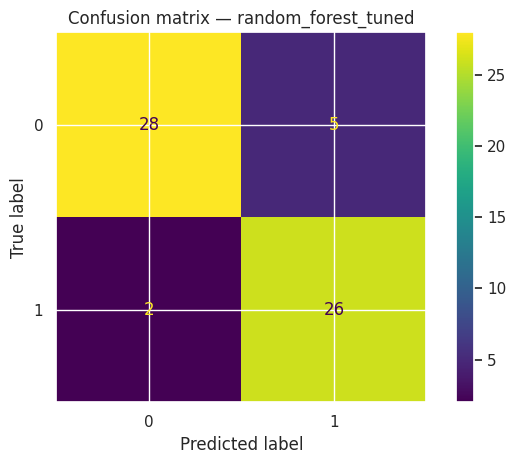

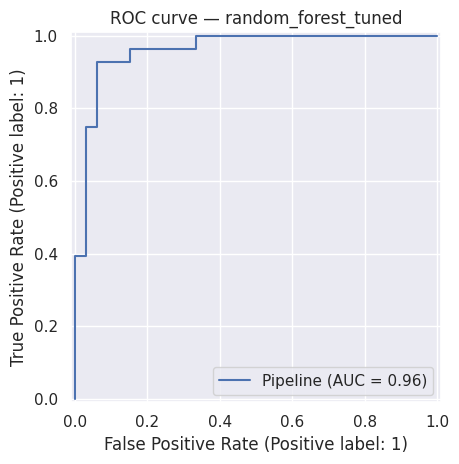

In [10]:
candidate_models = {
    "logistic_regression": best_lr,
    "random_forest_tuned": best_rf
}
evaluation_rows = []
for name, fitted_model in candidate_models.items():
    pred = fitted_model.predict(X_test)
    proba = fitted_model.predict_proba(X_test)[:, 1]
    evaluation_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba)
    })

evaluation_df = pd.DataFrame(evaluation_rows).sort_values("roc_auc", ascending=False)
display(evaluation_df)

# Select by training cross-validation ROC-AUC (not held-out test results).
cv_auc_by_candidate = {
    "logistic_regression": float(cv_df.loc["logistic_regression", "roc_auc"]),
    "random_forest_tuned": float(rf_search.best_score_),
}
best_name = max(cv_auc_by_candidate, key=cv_auc_by_candidate.get)
best_model = candidate_models[best_name]
print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_model.predict(X_test), zero_division=0))

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title(f"ROC curve — {best_name}")
plt.tight_layout()
plt.show()

## 10. MLflow experiment tracking

This section uses **MLflow for experiment tracking** with a SQLite backend. SQLite is only the tracking database backend; MLflow remains responsible for logging runs, parameters, metrics, models and artifacts.

The experiment will track both candidate models:
- Logistic Regression
- Tuned Random Forest

Each run records cross-validation ROC-AUC, held-out test metrics, model parameters and artifacts. Run this section only after model evaluation in Section 9 has completed successfully.

In [11]:
import mlflow
print("MLflow version:", mlflow.__version__)
print("Project directory:", PROJECT_DIR)

MLflow version: 3.17.0
Project directory: /content/drive/MyDrive/SEM_3/MLOPS/Assignment_01


In [12]:
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

# Persist MLflow tracking database and artifacts under the assignment folder.
MLFLOW_DB = PROJECT_DIR / "mlflow.db"
MLFLOW_ARTIFACTS = PROJECT_DIR / "mlartifacts"
MLFLOW_ARTIFACTS.mkdir(parents=True, exist_ok=True)

tracking_uri = f"sqlite:///{MLFLOW_DB.resolve().as_posix()}"
mlflow.set_tracking_uri(tracking_uri)

EXPERIMENT_NAME = "heart-disease-classification"
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        EXPERIMENT_NAME,
        artifact_location=MLFLOW_ARTIFACTS.resolve().as_uri()
    )
else:
    experiment_id = experiment.experiment_id
    expected_artifact_root = MLFLOW_ARTIFACTS.resolve().as_uri()
    if not experiment.artifact_location.startswith(expected_artifact_root):
        print(
            "WARNING: Existing experiment artifact location is:",
            experiment.artifact_location,
            "\nExisting experiments keep their original artifact location."
        )

mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", EXPERIMENT_NAME)
print("Experiment ID:", experiment_id)
print("Artifact directory for newly created experiment:", MLFLOW_ARTIFACTS)

MLflow version: 3.17.0
Tracking URI: sqlite:////content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/mlflow.db
Experiment: heart-disease-classification
Experiment ID: 1
Artifact directory for newly created experiment: /content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/mlartifacts


In [14]:

# Save comparison tables first
cv_csv = ARTIFACTS_DIR / "cross_validation_results.csv"
eval_csv = ARTIFACTS_DIR / "test_evaluation_results.csv"

cv_df.to_csv(cv_csv, index=True)
evaluation_df.to_csv(eval_csv, index=False)

# Match tuned model names to the cross-validation table
cv_name_map = {
    "logistic_regression": "logistic_regression",
    "random_forest_tuned": "random_forest",
}

logged_run_ids = []

for model_name, fitted_model in candidate_models.items():

    row = evaluation_df.loc[
        evaluation_df["model"] == model_name
    ].iloc[0]

    cv_name = cv_name_map[model_name]
    cv_roc_auc = float(cv_df.loc[cv_name, "roc_auc"])

    with mlflow.start_run(run_name=model_name) as run:
        logged_run_ids.append(run.info.run_id)

        mlflow.set_tag("assignment", "MLOps Assignment 01")
        mlflow.set_tag(
            "dataset", "UCI Heart Disease, repository ID 45"
        )
        mlflow.set_tag(
            "selected_model", str(model_name == best_name)
        )

        mlflow.log_params({
            "model_name": model_name,
            "dataset": "UCI Heart Disease (id=45)",
            "target_mapping": "0 -> 0; values > 0 -> 1",
            "random_state": 42,
            "test_size": 0.2,
            "cross_validation_folds": 5,
        })

        mlflow.log_metric("cv_roc_auc_mean", cv_roc_auc)

        if model_name == "random_forest_tuned":
            mlflow.log_params({
                key: value
                for key, value in rf_search.best_params_.items()
            })

        for metric in [
            "accuracy", "precision", "recall", "f1", "roc_auc"
        ]:
            mlflow.log_metric(
                f"test_{metric}", float(row[metric])
            )

        mlflow.log_artifact(
            str(cv_csv), artifact_path="evaluation"
        )
        mlflow.log_artifact(
            str(eval_csv), artifact_path="evaluation"
        )

        # Use float inputs in the model signature to support
        # numeric values that may contain missing data.
        sample_input = X_train.head(3).astype("float64")
        sample_output = fitted_model.predict(sample_input)

        signature = infer_signature(
            sample_input,
            sample_output
        )

        mlflow.sklearn.log_model(
            sk_model=fitted_model,
            name="model",
            input_example=sample_input,
            signature=signature,
            serialization_format="pickle",
        )

        print(
            f"Logged {model_name}; run_id={run.info.run_id}"
        )

print("\nMLflow experiment runs logged successfully.")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Logged run IDs:", logged_run_ids)


2026/10/09 19:47:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged logistic_regression; run_id=c549cec22c574cb194555966224a91ca


2026/10/09 19:47:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged random_forest_tuned; run_id=1c5d8f36c851472186a2950e7351c6aa

MLflow experiment runs logged successfully.
Tracking URI: sqlite:////content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/mlflow.db
Logged run IDs: ['c549cec22c574cb194555966224a91ca', '1c5d8f36c851472186a2950e7351c6aa']


In [15]:
experiment = mlflow.get_experiment_by_name(
    "heart-disease-classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print("Total tracked runs:", len(runs))
display(runs[[
    "tags.mlflow.runName",
    "status",
    "metrics.cv_roc_auc_mean",
    "metrics.test_accuracy",
    "metrics.test_recall",
    "metrics.test_roc_auc",
]])

Total tracked runs: 6


,tags.mlflow.runName,status,metrics.cv_roc_auc_mean,metrics.test_accuracy,metrics.test_recall,metrics.test_roc_auc
0,random_forest_tuned,FINISHED,0.884211,0.885246,0.928571,0.961039
1,logistic_regression,FINISHED,0.896305,0.868852,0.928571,0.950216
2,logistic_regression,FAILED,0.896305,0.868852,0.928571,0.950216
3,random_forest_tuned,FINISHED,NaN,NaN,NaN,NaN
4,logistic_regression,FINISHED,NaN,NaN,NaN,NaN
5,tracking-smoke-test,FINISHED,NaN,0.950000,NaN,NaN


## 10.1 Verify tracked MLflow runs

This cell should show completed MLflow runs for Logistic Regression and tuned Random Forest. If you previously ran a smoke test, it may also appear in the experiment history.

In [16]:
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["attributes.start_time DESC"]
)

print("Experiment:", experiment.name)
print("Total tracked runs:", len(runs))

display_columns = [
    "run_id", "tags.mlflow.runName", "status",
    "metrics.cv_roc_auc_mean", "metrics.test_accuracy",
    "metrics.test_precision", "metrics.test_recall",
    "metrics.test_f1", "metrics.test_roc_auc"
]
available_columns = [column for column in display_columns if column in runs.columns]
display(runs[available_columns])

Experiment: heart-disease-classification
Total tracked runs: 6


,run_id,tags.mlflow.runName,status,metrics.cv_roc_auc_mean,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc
0,1c5d8f36c851472186a2950e7351c6aa,random_forest_tuned,FINISHED,0.884211,0.885246,0.83871,0.928571,0.881356,0.961039
1,c549cec22c574cb194555966224a91ca,logistic_regression,FINISHED,0.896305,0.868852,0.81250,0.928571,0.866667,0.950216
2,4c15002469724504b32db7bd2867bd24,logistic_regression,FAILED,0.896305,0.868852,0.81250,0.928571,0.866667,0.950216
3,c82e9a674ae1407e8fec4e9523b8cd37,random_forest_tuned,FINISHED,NaN,NaN,NaN,NaN,NaN,NaN
4,c349575205644e7997f502c61285b978,logistic_regression,FINISHED,NaN,NaN,NaN,NaN,NaN,NaN
5,818aaa28d52948f8b4725c6fcc357d71,tracking-smoke-test,FINISHED,NaN,0.950000,NaN,NaN,NaN,NaN


## 11. Save the final model and feature contract

The saved artifact includes preprocessing and the estimator in one scikit-learn pipeline. Keep the ordered feature list to validate incoming API payloads. Pickle/joblib artifacts should only be loaded from trusted sources.

In [17]:
import joblib

MODEL_PATH = ARTIFACTS_DIR / "heart_disease_pipeline.joblib"
FEATURES_PATH = ARTIFACTS_DIR / "feature_columns.json"
METRICS_PATH = ARTIFACTS_DIR / "final_metrics.json"

joblib.dump(best_model, MODEL_PATH)
FEATURES_PATH.write_text(json.dumps(numeric_features, indent=2))
final_row = evaluation_df[evaluation_df["model"] == best_name].iloc[0].to_dict()
final_row["selected_model"] = best_name
final_row["feature_columns"] = numeric_features
METRICS_PATH.write_text(json.dumps(final_row, indent=2, default=float))

print("Saved model:", MODEL_PATH)
print("Saved features:", FEATURES_PATH)
print("Saved metrics:", METRICS_PATH)

Saved model: /content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/artifacts/heart_disease_pipeline.joblib
Saved features: /content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/artifacts/feature_columns.json
Saved metrics: /content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/artifacts/final_metrics.json


In [19]:

from pathlib import Path
import joblib
import numpy as np

# Use the portable project path defined in setup cell 0.

FINAL_MODEL_PATH = (
    PROJECT_DIR / "artifacts" / "heart_disease_pipeline.joblib"
)

# Check that the saved file exists
assert FINAL_MODEL_PATH.exists(), (
    f"Model file not found: {FINAL_MODEL_PATH}"
)

# Load the saved model
loaded_model = joblib.load(FINAL_MODEL_PATH)

# Test predictions on held-out test data
sample = X_test.head(5)
predictions = loaded_model.predict(sample)
probabilities = loaded_model.predict_proba(sample)[:, 1]

print("Loaded model:", type(loaded_model).__name__)
print("Model path:", FINAL_MODEL_PATH)
print("Predictions:", predictions)
print("Positive-class probabilities:", np.round(probabilities, 4))

# Validate the output
assert len(predictions) == len(sample)
assert set(predictions).issubset({0, 1})
assert np.all((probabilities >= 0) & (probabilities <= 1))

print("\nModel save and reload verification passed.")


Loaded model: Pipeline
Model path: /content/drive/MyDrive/SEM_3/MLOPS/Assignment_01/artifacts/heart_disease_pipeline.joblib
Predictions: [0 1 0 0 0]
Positive-class probabilities: [0.3252 0.6666 0.0918 0.0881 0.4075]

Model save and reload verification passed.


## 12. Review reusable source code and API

The repository source files are kept as normal `.py` files instead of being generated from the notebook. This avoids overwriting the final API or tests when the notebook is rerun. The next cell checks that the API and prediction helper exist and shows the main files used for serving.


In [ ]:
from pathlib import Path

source_files = [
    SRC_DIR / "__init__.py",
    SRC_DIR / "predict.py",
    SRC_DIR / "api.py",
]
for file_path in source_files:
    assert file_path.exists(), f"Missing source file: {file_path}"
    print(f"\n--- {file_path.relative_to(PROJECT_DIR)} ---")
    print(file_path.read_text()[:3000])


## 13. Review unit tests

The tests cover API readiness, feature validation, and a basic prediction response. They use the saved model artifact, so run the training section before running the tests.


In [ ]:
test_file = TESTS_DIR / "test_api.py"
assert test_file.exists(), f"Missing test file: {test_file}"
print(test_file.read_text())


## 14. Review reproducible dependency file and project configuration

The dependency file is maintained in the repository. It is checked here so the notebook record matches the files submitted for the assignment.


In [ ]:
requirements_path = PROJECT_DIR / "requirements.txt"
gitignore_path = PROJECT_DIR / ".gitignore"
assert requirements_path.exists(), "requirements.txt is missing"
assert gitignore_path.exists(), ".gitignore is missing"

print("--- requirements.txt ---")
print(requirements_path.read_text())
print("--- .gitignore ---")
print(gitignore_path.read_text())


## 15. Review Dockerfile and GitHub Actions CI workflow

The CI workflow installs dependencies, trains the model artifacts, runs linting checks, and executes tests. These files are shown here as submission evidence rather than regenerated from the notebook.


In [ ]:
dockerfile_path = PROJECT_DIR / "Dockerfile"
workflow_path = WORKFLOWS_DIR / "ci.yml"
assert dockerfile_path.exists(), "Dockerfile is missing"
assert workflow_path.exists(), "GitHub Actions workflow is missing"

print("--- Dockerfile ---")
print(dockerfile_path.read_text())
print("--- .github/workflows/ci.yml ---")
print(workflow_path.read_text())


## 16. Review Kubernetes deployment manifest

The manifest can be used for a local Kubernetes run. If pushing to a registry, update the image name before applying it.


In [ ]:
k8s_path = DEPLOYMENT_DIR / "kubernetes.yaml"
assert k8s_path.exists(), "Kubernetes manifest is missing"
print(k8s_path.read_text())


## 17. Review README/report notes

The repository README contains setup, training, API, Docker, Kubernetes, and result notes. The final report should add screenshots and verification evidence.


In [ ]:
readme_path = PROJECT_DIR / "README.md"
assert readme_path.exists(), "README.md is missing"
print(readme_path.read_text())


## 18. Run unit tests and API smoke checks

This starts a local test client; it does not need a publicly exposed server. If the tests fail, inspect the error output and fix that before continuing. Lint warnings should also be addressed before pushing the repository.

In [26]:
# Ensure project root is importable
import sys
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", str(TESTS_DIR)],
    cwd=str(PROJECT_DIR),
    text=True,
    capture_output=True
)
print(result.stdout)
print(result.stderr)
print("pytest exit code:", result.returncode)
if result.returncode != 0:
    raise RuntimeError("Tests failed. Review the output before continuing.")

....                                                                     [100%]
4 passed in 2.10s


pytest exit code: 0


## 19. Build an archive for submission

This creates a ZIP of the project excluding raw generated MLflow tracking data and notebook runtime caches. The ZIP includes source code, tests, deployment files, and the trained model artifacts for API verification.


In [ ]:
# Create a ZIP archive for submission.
# Include source code, requirements, deployment files, and trained model artifacts.
# Exclude MLflow's SQLite database and run artifacts to avoid copying an open
# database or creating a large archive.
ARCHIVE_BASE = PROJECT_DIR.parent / "MLOps_Assignment_01_transfer"
archive_path = ARCHIVE_BASE.with_suffix(".zip")
if archive_path.exists():
    archive_path.unlink()

import zipfile

with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in PROJECT_DIR.rglob("*"):
        if not file_path.is_file():
            continue
        relative = file_path.relative_to(PROJECT_DIR)
        parts = set(relative.parts)
        if parts.intersection({"mlartifacts", "mlruns", "__pycache__", ".ipynb_checkpoints"}):
            continue
        if relative.name in {"mlflow.db"} or relative.suffix == ".pyc":
            continue
        zf.write(file_path, relative)

print("Archive created:", archive_path)


## 20. Final checklist before submission

Do not mark an item complete until you have actually run and verified it.

- [ ] Dataset download and raw data saved
- [ ] EDA plots generated and interpreted
- [ ] Two models trained and compared with cross-validation
- [ ] Test metrics recorded
- [ ] MLflow runs and artifacts created
- [ ] Model and feature contract saved
- [ ] API health and prediction endpoints tested
- [ ] Unit tests pass
- [ ] Linting passes
- [ ] Docker image builds and container runs locally
- [ ] CI workflow runs successfully on GitHub
- [ ] Deployment target works and screenshots captured
- [ ] API logs/monitoring evidence captured
- [ ] Final report and short pipeline video completed
- [ ] Critical checks repeated in the final submission environment
